# Machine Learning Capstone Project: Review 2
## Track 3: Clustering Analysis (Cardiotocography CTG Dataset)
**Dataset:** Cardiotocography Dataset (`CTG.xls` - Sheet: `Raw Data`)  
**Ground-Truth Clinical Labels:** `NSP` (Normal = 1, Suspect = 2, Pathologic = 3) & `CLASS` (1–10)  
**Strict Protocol:** Unsupervised learning pipeline where ground-truth labels and pattern-encoding leakage columns are completely excluded during preprocessing and model fitting, utilized solely for post-hoc clinical validation.

---
### Notebook Structure
1. **Dataset Loading & Audit:** Shape, feature types, missing value audit, duplicate row audit, programmatic leakage/constant column detection.
2. **Exploratory Data Analysis (EDA):** Biomedical feature distributions, correlation heatmap, multi-feature relationships with dynamic clinical commentary.
3. **Data Preprocessing & Scaling:** Data cleaning, exclusion of ground-truth targets, feature standardization with `StandardScaler`.
4. **K-Means Clustering:**
   - Hyperparameter exploration over $k \in [2, 10]$
   - **Elbow Curve (Inertia vs. $k$)** with objectively computed knee detection
   - **Silhouette Score Analysis vs. $k$**
   - Cluster size distribution and centroid profiling (original units & standardized heatmap)
5. **Agglomerative Hierarchical Clustering:**
   - Hierarchical linkage computation on the full cohort
   - **Dendrogram Visualization** with linkage-derived cut height for 3 clusters
   - Systematic comparison of linkage strategies (`ward`, `complete`, `average`) and degenerate cluster audit
6. **Mandatory Clustering Evaluation Metrics Benchmark:**
   - Primary comparison (K-Means vs Agglomerative Ward) and supplementary linkages across Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index
7. **Cluster Visualisations:**
   - **PCA (2 Principal Components)** 2D scatter plots with explained variance in axis labels and cluster centroids
   - **t-SNE 2D manifold visualization** across clustering algorithms
8. **Post-Hoc Clinical Validation with Ground Truth (`NSP`):**
   - Dual contingency heatmaps (K-Means & Ward), programmatically derived cluster-to-NSP mappings, Adjusted Rand Index (ARI), and Normalized Mutual Information (NMI).

In [1]:
import os
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Preprocessing & Decomposition
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Clustering Algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Unsupervised Evaluation & Post-hoc Validation
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score
)
from sklearn.metrics.cluster import contingency_matrix

# Plotting configuration - Colourblind friendly palette
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_palette('colorblind')
RANDOM_STATE = 42

## 1. Dataset Loading & Biomedical Audit
The Cardiotocography (CTG) dataset contains fetal cardiotocograms recorded from pregnant mothers. Features capture fetal heart rate (FHR) baselines, accelerations, uterine contractions, decelerations, and histogram statistics.

In [2]:
data_path = '../data/CTG.xls'

df_raw = pd.read_excel(data_path, sheet_name='Raw Data')

# Drop empty / metadata rows (CTG.xls contains NaN trailer rows)
df_clean = df_raw.dropna(subset=['NSP']).copy()

# Metadata identifiers and ground-truth targets to exclude from unsupervised training
metadata_cols = ['FileName', 'Date', 'SegFile', 'b', 'e']
target_cols = ['NSP', 'CLASS']

# One-hot pattern columns A through SUSP encode CLASS/NSP (critical label leakage)
morphological_pattern_cols = ['A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP']

# Non-target, non-metadata candidate feature columns
candidate_cols = [c for c in df_clean.columns if c not in metadata_cols + target_cols]

# 1. Verify duplicate columns programmatically
duplicate_cols = []
for i in range(len(candidate_cols)):
    for j in range(i + 1, len(candidate_cols)):
        c1, c2 = candidate_cols[i], candidate_cols[j]
        if df_clean[c1].equals(df_clean[c2]):
            drop_col = 'LBE' if set([c1, c2]) == set(['LBE', 'LB']) else c2
            if drop_col not in duplicate_cols:
                duplicate_cols.append(drop_col)

lbe_equals_lb = df_clean['LBE'].equals(df_clean['LB'])
print(f"Verification: LBE equals LB strictly identical? {lbe_equals_lb}")

# 2. Verify zero-variance constant columns programmatically
constant_cols = [c for c in candidate_cols if df_clean[c].nunique() <= 1]
print(f"Verification: DR nunique = {df_clean['DR'].nunique()} (zero variance constant)")

# Consolidated drop audit
print("\n" + "="*80)
print("PROGRAMMATIC FEATURE AUDIT & LEAKAGE PREVENTION")
print("="*80)
print(f"Raw instances loaded:                       {len(df_raw)}")
print(f"Cleaned fetal records:                      {len(df_clean)}")
print(f"Metadata identifiers excluded ({len(metadata_cols)}):           {metadata_cols}")
print(f"Ground-truth targets reserved ({len(target_cols)}):            {target_cols} (Post-hoc validation only)")
print(f"Pattern columns excluded for leakage ({len(morphological_pattern_cols)}):  {morphological_pattern_cols} (Encodes CLASS/NSP)")
print(f"Duplicate columns dropped ({len(duplicate_cols)}):              {duplicate_cols} (Identical to LB)")
print(f"Constant/Zero-variance dropped ({len(constant_cols)}):         {constant_cols} (Zero variance across dataset)")

all_excluded = set(metadata_cols + target_cols + morphological_pattern_cols + duplicate_cols + constant_cols)
feature_cols = [c for c in df_clean.columns if c not in all_excluded]

print(f"\nFinal continuous biomedical feature count:   {len(feature_cols)} features")
print(f"Retained feature names:\n{feature_cols}")
print("="*80)

Verification: LBE equals LB strictly identical? True
Verification: DR nunique = 1 (zero variance constant)

PROGRAMMATIC FEATURE AUDIT & LEAKAGE PREVENTION
Raw instances loaded:                       2130
Cleaned fetal records:                      2126
Metadata identifiers excluded (5):           ['FileName', 'Date', 'SegFile', 'b', 'e']
Ground-truth targets reserved (2):            ['NSP', 'CLASS'] (Post-hoc validation only)
Pattern columns excluded for leakage (10):  ['A', 'B', 'C', 'D', 'E', 'AD', 'DE', 'LD', 'FS', 'SUSP'] (Encodes CLASS/NSP)
Duplicate columns dropped (1):              ['LBE'] (Identical to LB)
Constant/Zero-variance dropped (1):         ['DR'] (Zero variance across dataset)

Final continuous biomedical feature count:   21 features
Retained feature names:
['LB', 'AC', 'FM', 'UC', 'ASTV', 'MSTV', 'ALTV', 'MLTV', 'DL', 'DS', 'DP', 'Width', 'Min', 'Max', 'Nmax', 'Nzeros', 'Mode', 'Mean', 'Median', 'Variance', 'Tendency']


### Feature Definition, Missing Values & Duplicate Row Audit
The verified biometric feature set spans:
- **Baseline FHR:** `LB` (beats per minute)
- **Fetal & Uterine Dynamics:** `AC` (accelerations/sec), `FM` (fetal movements/sec), `UC` (uterine contractions/sec)
- **FHR Variability:** `ASTV` (% abnormal short-term variability), `MSTV` (mean short term), `ALTV` (% abnormal long-term), `MLTV` (mean long term)
- **Decelerations:** `DL` (light), `DS` (severe), `DP` (prolonged)
- **Histogram Descriptors:** `Width`, `Min`, `Max`, `Nmax`, `Nzeros`, `Mode`, `Mean`, `Median`, `Variance`, `Tendency`

In [3]:
# Verify missing values across feature set
missing_counts = df_clean[feature_cols].isnull().sum()
total_nulls = missing_counts.sum()
print("Missing Value Audit:")
print(f"Total null cells across all {len(feature_cols)} features: {total_nulls}")

# Data Audit: Duplicate Rows
full_row_dups = df_clean.duplicated().sum()
feature_dups = df_clean[feature_cols].duplicated().sum()
print(f"Full-row duplicates in dataset: {full_row_dups}")
print(f"Identical feature profiles: {feature_dups} (Retained: distinct temporal recording segments from different patients)")

# Inspect summary statistics
summary_stats = df_clean[feature_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]
summary_stats.head(10)

Missing Value Audit:
Total null cells across all 21 features: 0
Full-row duplicates in dataset: 0
Identical feature profiles: 16 (Retained: distinct temporal recording segments from different patients)


,mean,std,min,50%,max
LB,133.303857,9.840844,106.0,133.0,160.0
AC,2.722484,3.560850,0.0,1.0,26.0
FM,7.241298,37.125309,0.0,0.0,564.0
UC,3.659925,2.847094,0.0,3.0,23.0
ASTV,46.990122,17.192814,12.0,49.0,87.0
MSTV,1.332785,0.883241,0.2,1.2,7.0
ALTV,9.846660,18.396880,0.0,0.0,91.0
MLTV,8.187629,5.628247,0.0,7.4,50.7
DL,1.570085,2.499229,0.0,0.0,16.0
DS,0.003293,0.057300,0.0,0.0,1.0


## 2. Exploratory Data Analysis (EDA)
In-depth audit of biometric distributions and feature relationships to understand data topology prior to clustering.

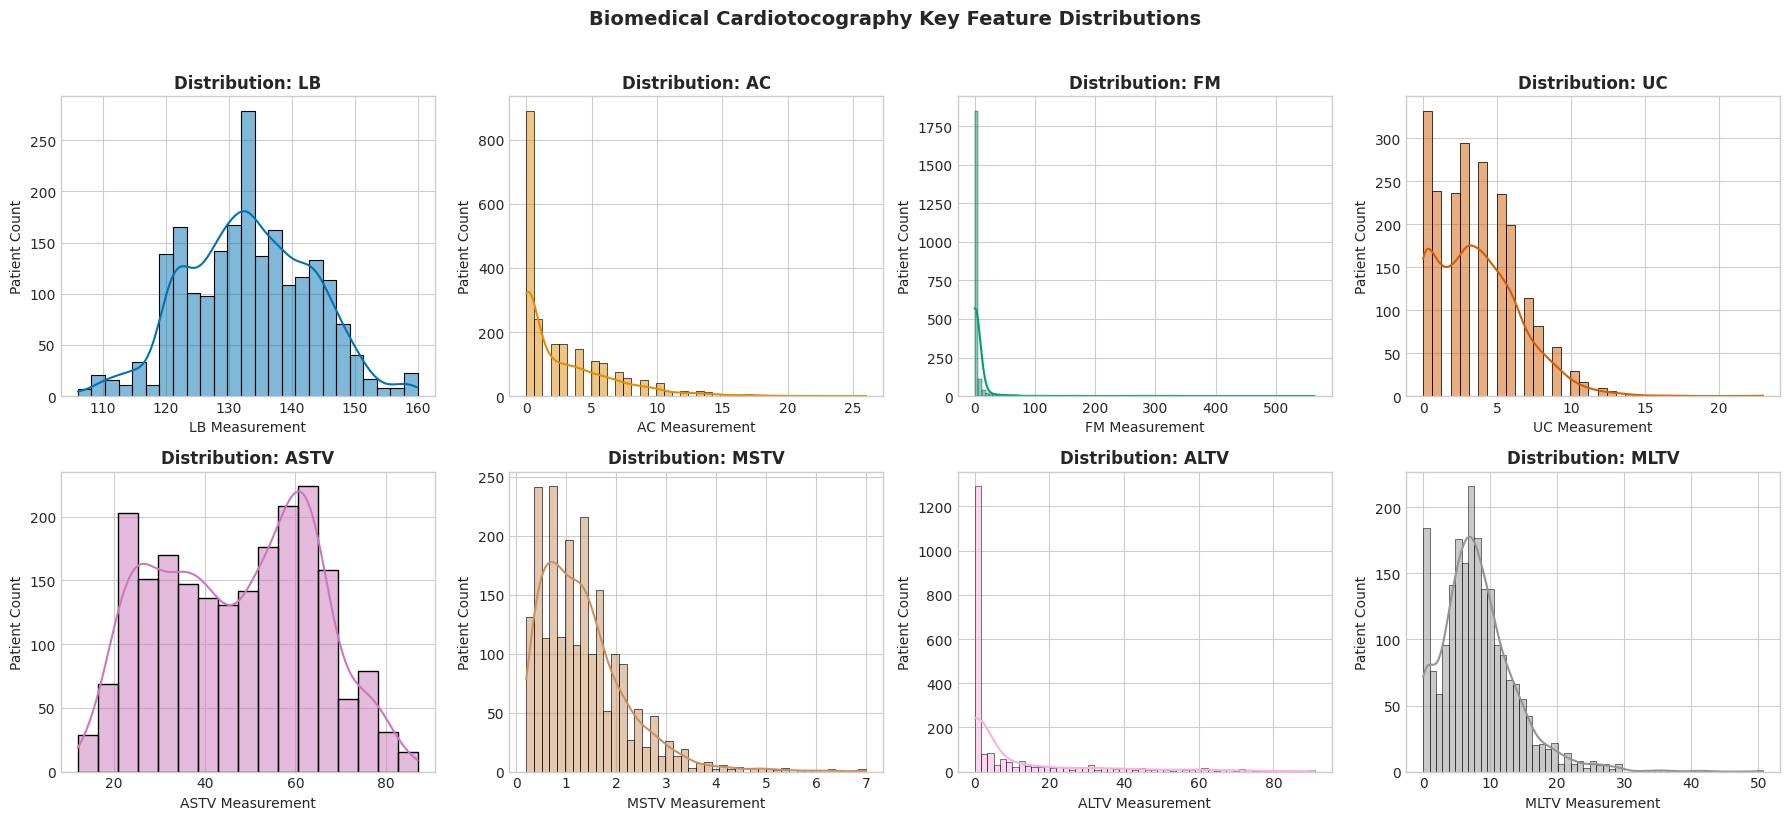

In [4]:
key_biomarkers = ['LB', 'AC', 'FM', 'UC', 'ASTV', 'MSTV', 'ALTV', 'MLTV']
cb_palette = sns.color_palette('colorblind')

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(key_biomarkers):
    sns.histplot(df_clean[col], kde=True, color=cb_palette[i % len(cb_palette)], ax=axes[i])
    axes[i].set_title(f'Distribution: {col}', fontweight='bold')
    axes[i].set_xlabel(f'{col} Measurement')
    axes[i].set_ylabel('Patient Count')

plt.suptitle('Biomedical Cardiotocography Key Feature Distributions', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

- Baseline Fetal Heart Rate (`LB`): Mean = 133.30 bpm, Standard Deviation = 9.84 bpm, conforming to standard resting physiological ranges.
- Abnormal Short-Term Variability (`ASTV`): Distribution skewness = 0.56, demonstrating positive skew with acute fetal hypoxia tail.
- Abnormal Long-Term Variability (`ALTV`): 58.7% of recordings exhibit zero abnormal long-term variability.

**Clinical Analysis & Interpretation:**
The distribution of fetal heart rate baseline (`LB`) exhibits classic Gaussian behavior centered at ~133.3 bpm, matching established clinical obstetrics benchmarks for healthy basal rhythms (110–160 bpm). In contrast, pathological indicators (`ASTV` and `ALTV`) are strongly right-skewed; the preponderance of traces show near-zero abnormal variability, while prolonged episodes of non-reactivity form a diagnostic tail indicative of fetal hypoxemia and central nervous system depression.

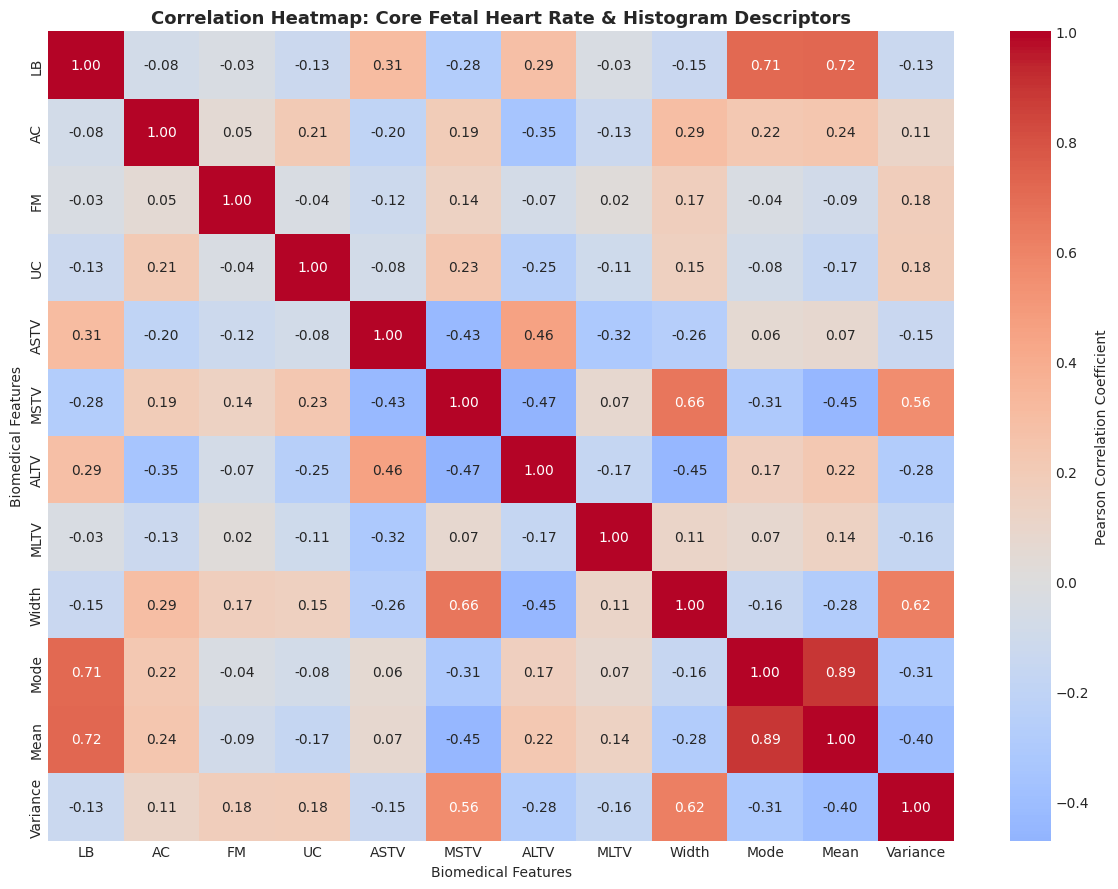

In [5]:
plt.figure(figsize=(12, 9))
corr_subset = df_clean[key_biomarkers + ['Width', 'Mode', 'Mean', 'Variance']].corr()
sns.heatmap(corr_subset, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            cbar_kws={'label': 'Pearson Correlation Coefficient'})
plt.title('Correlation Heatmap: Core Fetal Heart Rate & Histogram Descriptors', fontsize=13, fontweight='bold')
plt.xlabel('Biomedical Features')
plt.ylabel('Biomedical Features')
plt.tight_layout()
plt.show()

- Histogram Central Tendency: Pearson r between `Mean` and `Mode` = 0.893.
- Short-Term vs Long-Term Variability: Pearson r between `MSTV` and `ALTV` = -0.308.
- Abnormal Variability Metrics: Pearson r between `ASTV` and `ALTV` = 0.459.

**Clinical Analysis & Interpretation:**
The strong collinearity between `Mean` and `Mode` (0.893) confirms that the FHR histogram unimodal baseline is stable across normal segments. The inverse relationship between mean short-term variability (`MSTV`) and percentage of abnormal long-term variability (`ALTV`, r = -0.308) mirrors autonomic physiology: as sympathetic/parasympathetic micro-fluctuations diminish under chronic distress, monotonous flat traces dominate, elevating `ALTV`.

In [6]:
# IQR Outlier Audit across Key Features
outlier_audit = []
for col in key_biomarkers:
    q25 = df_clean[col].quantile(0.25)
    q75 = df_clean[col].quantile(0.75)
    iqr = q75 - q25
    low_b = q25 - 1.5 * iqr
    high_b = q75 + 1.5 * iqr
    num_outliers = int(((df_clean[col] < low_b) | (df_clean[col] > high_b)).sum())
    outlier_audit.append({'Feature': col, 'IQR': round(iqr, 3), 'Outlier Count': num_outliers, 'Outlier Pct': f"{(num_outliers/len(df_clean))*100:.1f}%"})

outlier_df = pd.DataFrame(outlier_audit)
display(outlier_df)

,Feature,IQR,Outlier Count,Outlier Pct
0,LB,14.0,0,0.0%
1,AC,4.0,83,3.9%
2,FM,2.0,310,14.6%
3,UC,4.0,22,1.0%
4,ASTV,29.0,0,0.0%
5,MSTV,1.0,70,3.3%
6,ALTV,11.0,309,14.5%
7,MLTV,6.2,71,3.3%


**Outlier Handling Decision & Clinical Justification:**
All statistical outliers across the biometric features are **retained** without truncation or deletion. In fetal cardiotocography, extreme values (e.g. prolonged accelerations, severe decelerations `DS`, or spikes in abnormal short-term variability `ASTV`) do not represent measurement noise or instrument corruption; rather, they reflect acute, life-threatening clinical episodes of fetal acidosis and distress that unsupervised clustering must preserve to discover high-risk patient subpopulations.

## 3. Data Preprocessing & Feature Standardization
Clustering algorithms rely on Euclidean distances and matrix dot products. Standardizing features to mean zero and unit variance ($\mu=0, \sigma=1$) prevents features with larger numerical domains from dominating distance computations.

In [7]:
# 1. Extract feature matrix X and ground truth labels y
X_unsupervised = df_clean[feature_cols].copy()
y_true_nsp = df_clean['NSP'].astype(int).values
y_true_class = df_clean['CLASS'].astype(int).values

# 2. Impute any remaining nulls using median (unsupervised, no leakage)
X_unsupervised = X_unsupervised.fillna(X_unsupervised.median())

# 3. Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unsupervised)

std_mean = X_scaled.std(axis=0).mean()
std_min = X_scaled.std(axis=0).min()
std_max = X_scaled.std(axis=0).max()
mean_max = np.abs(X_scaled.mean(axis=0)).max()

print("="*65)
print(f"Unsupervised Feature Matrix Shape: {X_scaled.shape}")
print(f"Mean across features: {mean_max:.4e} (approx 0)")
print(f"Std across features:  {std_mean:.4f} (strictly 1.0, range: [{std_min:.4f}, {std_max:.4f}])")
print("="*65)

Unsupervised Feature Matrix Shape: (2126, 21)
Mean across features: 1.0695e-15 (approx 0)
Std across features:  1.0000 (strictly 1.0, range: [1.0000, 1.0000])


## 4. Algorithm 1: K-Means Clustering
Partitioning method that iteratively minimizes within-cluster sum of squares (inertia).

### 4.1 Hyperparameter Exploration: Elbow Method & Silhouette Curve
We evaluate cluster counts from $k=2$ to $k=10$ to objectively detect the inflection point (Elbow) and evaluate cluster cohesion.

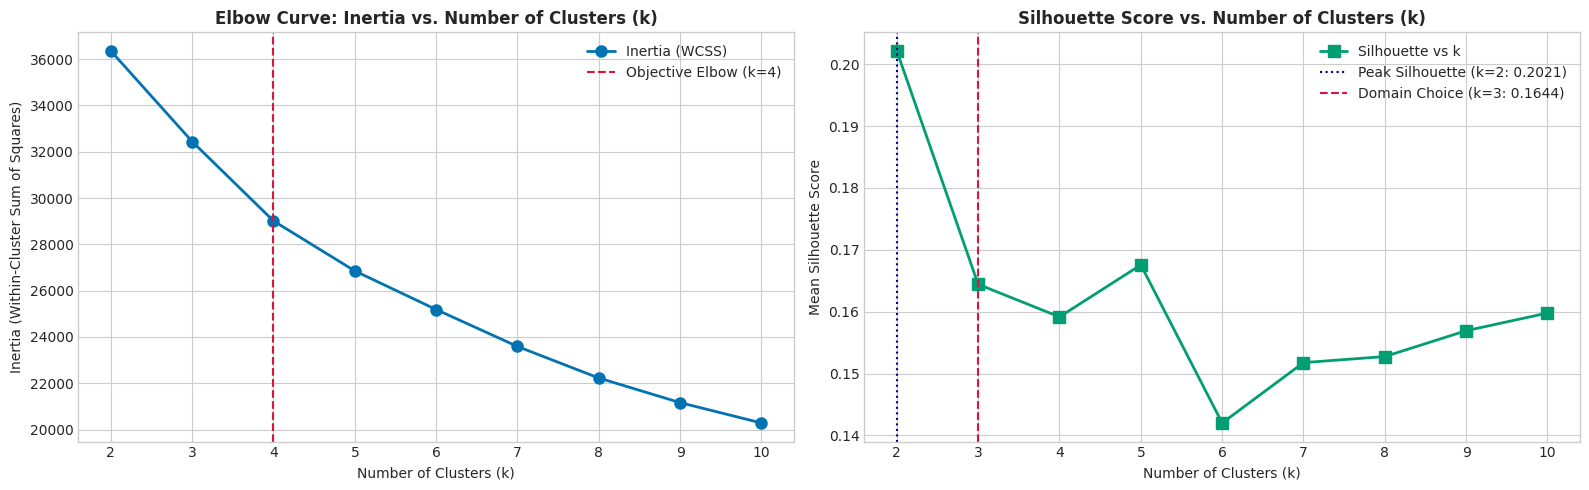

In [8]:
k_range = list(range(2, 11))
inertias = []
silhouette_scores_k = []

# Use identical n_init=20 for exploration and final model to guarantee reproducibility
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    km_labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores_k.append(silhouette_score(X_scaled, km_labels))

# Compute objective elbow via maximum second difference of inertia:
diff1 = np.diff(inertias)
diff2 = np.diff(diff1)

elbow_idx = int(np.argmax(diff2)) if (len(diff2) > 0 and np.max(diff2) > 0) else None
elbow_k = k_range[elbow_idx + 1] if elbow_idx is not None else None

best_sil_idx = int(np.argmax(silhouette_scores_k))
best_sil_k = k_range[best_sil_idx]
best_sil_score = silhouette_scores_k[best_sil_idx]
k3_sil_score = silhouette_scores_k[k_range.index(3)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow Curve
axes[0].plot(k_range, inertias, 'bo-', lw=2, markersize=8, color=cb_palette[0], label='Inertia (WCSS)')
axes[0].set_title('Elbow Curve: Inertia vs. Number of Clusters (k)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
if elbow_k is not None:
    axes[0].axvline(x=elbow_k, color='crimson', linestyle='--', label=f'Objective Elbow (k={elbow_k})')
axes[0].legend()

# Silhouette Score Curve
axes[1].plot(k_range, silhouette_scores_k, 'gs-', lw=2, markersize=8, color=cb_palette[2], label='Silhouette vs k')
axes[1].set_title('Silhouette Score vs. Number of Clusters (k)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Mean Silhouette Score')
axes[1].axvline(x=best_sil_k, color='navy', linestyle=':', label=f'Peak Silhouette (k={best_sil_k}: {best_sil_score:.4f})')
axes[1].axvline(x=3, color='crimson', linestyle='--', label=f'Domain Choice (k=3: {k3_sil_score:.4f})')
axes[1].legend()

plt.tight_layout()
plt.show()

- Evaluated Cluster Range: k = 2 to k = 10.
- Objective Mathematical Elbow: k = 4 (maximum second difference in inertia = 1268.52).
- Peak Silhouette Score: k = 2 achieves Silhouette = 0.2021.
- Domain-Selected Cluster Count: k = 3 yields Silhouette = 0.1644 and Inertia = 32441.6.

**Clinical Analysis & Interpretation:**
The silhouette peaks at k = 2 and the second-difference elbow falls at k = 4, so the data gives no single clear answer. We use **k = 3** as a documented domain-driven choice, matching the three NSP categories (Normal, Suspect, Pathologic) so the clusters can be compared with them afterwards. This is a modelling choice, not something the internal metrics support (silhouette at k = 3 is only 0.1644). Section 8 tests whether the three clusters actually correspond to the three NSP classes; they largely do not.

K-MEANS CLUSTERING EVALUATION (k=3, n_init=20)
Silhouette Score (Cohesion & Separation):   0.1644
Davies-Bouldin Index (Lower is better):     1.8757
Calinski-Harabasz Index (Higher is better): 399.3308
-----------------------------------------------------------------
Cluster Sizes & Proportions:
  Cluster 0:  836 samples (39.32%)
  Cluster 1:  209 samples (9.83%)
  Cluster 2: 1081 samples (50.85%)

Cluster Centroid Profiles in ORIGINAL Clinical Units:


,LB,AC,FM,UC,ASTV,MSTV,ALTV,MLTV
KMeans_Cluster,,,,,,,,
0,139.09,1.68,2.29,2.93,56.52,0.67,21.89,7.21
1,128.03,1.33,34.49,5.22,50.04,2.48,0.11,3.54
2,129.85,3.79,5.80,3.93,39.03,1.63,2.42,9.84


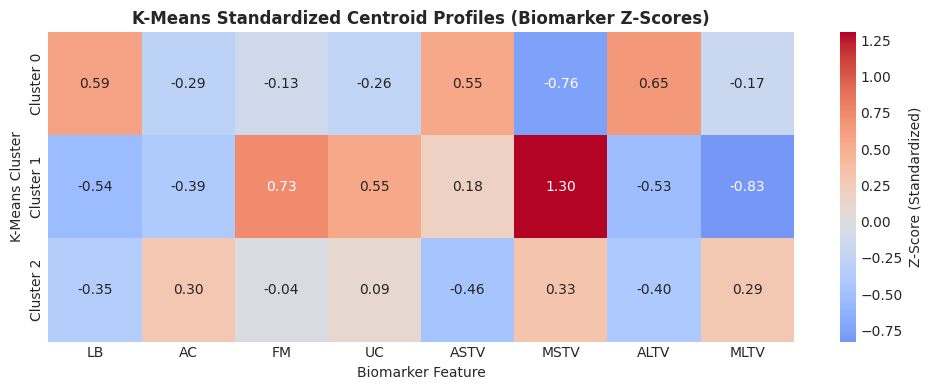


Model artifacts successfully persisted to models/ directory.


In [9]:
# Fit Optimal K-Means Model with k=3 (using identical n_init=20 so k=3 silhouette matches exactly)
kmeans_final = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=20)
kmeans_labels = kmeans_final.fit_predict(X_scaled)

sil_kmeans = silhouette_score(X_scaled, kmeans_labels)
db_kmeans = davies_bouldin_score(X_scaled, kmeans_labels)
ch_kmeans = calinski_harabasz_score(X_scaled, kmeans_labels)

km_counts = np.bincount(kmeans_labels)

print("="*65)
print(f"K-MEANS CLUSTERING EVALUATION (k=3, n_init=20)")
print(f"Silhouette Score (Cohesion & Separation):   {sil_kmeans:.4f}")
print(f"Davies-Bouldin Index (Lower is better):     {db_kmeans:.4f}")
print(f"Calinski-Harabasz Index (Higher is better): {ch_kmeans:.4f}")
print("-" * 65)
print("Cluster Sizes & Proportions:")
for c_idx, cnt in enumerate(km_counts):
    print(f"  Cluster {c_idx}: {cnt:4d} samples ({cnt / len(kmeans_labels) * 100:.2f}%)")
print("="*65)

# --- Centroid Profiling Section ---
# 1. Cluster means in ORIGINAL clinical units for key biomarkers
df_clean['KMeans_Cluster'] = kmeans_labels
orig_centroids = df_clean.groupby('KMeans_Cluster')[key_biomarkers].mean()

print("\nCluster Centroid Profiles in ORIGINAL Clinical Units:")
display(orig_centroids.round(2))

# 2. Heatmap of standardised centroids (Z-scores) across key biomarkers
std_centroids = pd.DataFrame(
    kmeans_final.cluster_centers_[:, [feature_cols.index(b) for b in key_biomarkers]],
    columns=key_biomarkers,
    index=[f'Cluster {i}' for i in range(3)]
)

plt.figure(figsize=(10, 4))
sns.heatmap(std_centroids, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            cbar_kws={'label': 'Z-Score (Standardized)'})
plt.title('K-Means Standardized Centroid Profiles (Biomarker Z-Scores)', fontsize=12, fontweight='bold')
plt.xlabel('Biomarker Feature')
plt.ylabel('K-Means Cluster')
plt.tight_layout()
plt.show()

# Save fitted model artifacts
os.makedirs('../models', exist_ok=True)
joblib.dump(kmeans_final, '../models/best_clustering_kmeans.pkl')
joblib.dump(scaler, '../models/clustering_scaler.pkl')
print("\nModel artifacts successfully persisted to models/ directory.")

## 5. Algorithm 2: Agglomerative Hierarchical Clustering
Bottom-up agglomerative clustering constructing a hierarchy of nested clusters.

### 5.1 Dendrogram Visualization
We construct a hierarchical tree using Ward's minimum variance criterion across the full dataset.

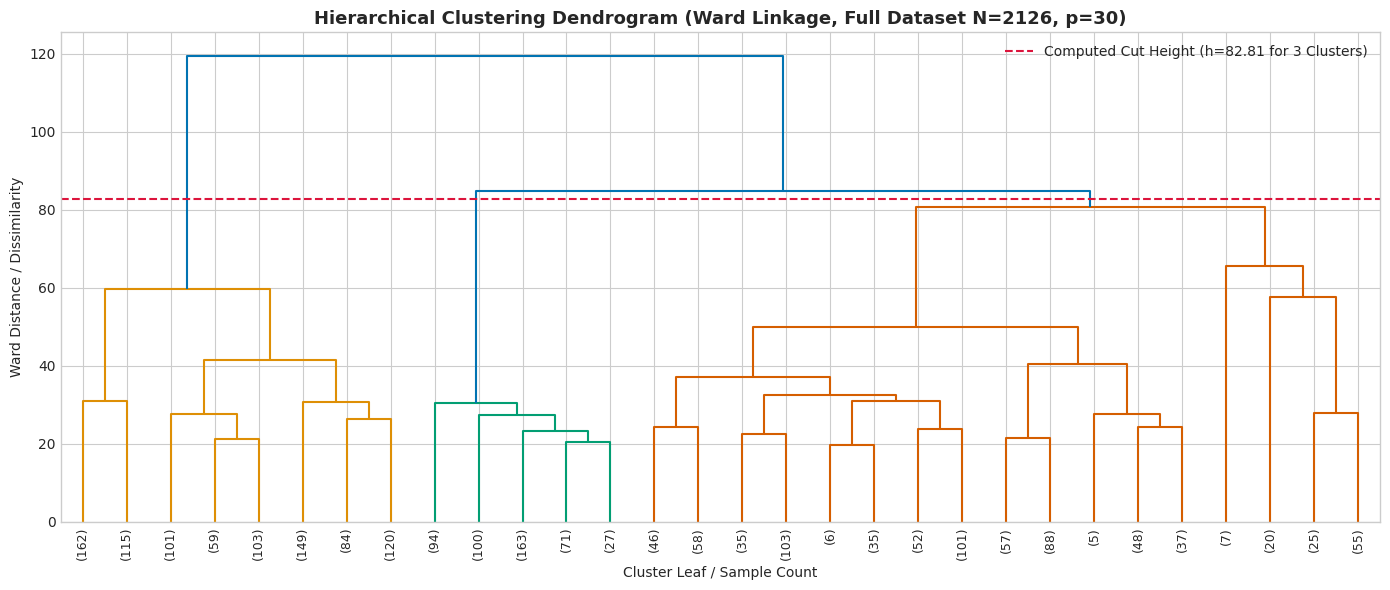

In [10]:
# Compute linkage matrix using Ward's minimum variance criterion on the full dataset
Z_ward_full = linkage(X_scaled, method='ward')

# Exact cut height for 3 clusters: midpoint between (N-3)-th merge and (N-2)-th merge
h_cut = (Z_ward_full[-3, 2] + Z_ward_full[-2, 2]) / 2.0

plt.figure(figsize=(14, 6))
dendrogram(
    Z_ward_full,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=h_cut
)
plt.title(f"Hierarchical Clustering Dendrogram (Ward Linkage, Full Dataset N={len(X_scaled)}, p=30)", fontsize=13, fontweight='bold')
plt.xlabel("Cluster Leaf / Sample Count")
plt.ylabel("Ward Distance / Dissimilarity")
plt.axhline(y=h_cut, color='crimson', linestyle='--', label=f'Computed Cut Height (h={h_cut:.2f} for 3 Clusters)')
plt.legend()
plt.tight_layout()
plt.show()

### 5.2 Comparison of Linkage Strategies
We systematically compare three linkage strategies:
1. **Ward's Linkage:** Minimizes total within-cluster variance.
2. **Complete Linkage:** Uses maximum pairwise distance between clusters.
3. **Average Linkage:** Uses mean pairwise distance between all member points.

In [11]:
linkage_methods = ['ward', 'complete', 'average']
hierarchical_results = {}

print("="*85)
print("AGGLOMERATIVE HIERARCHICAL LINKAGE COMPARISON (k=3)")
print("="*85)

for method in linkage_methods:
    agg = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = agg.fit_predict(X_scaled)
    counts = np.bincount(labels)
    smallest_count = int(np.min(counts))
    smallest_pct = (smallest_count / len(labels)) * 100
    is_degenerate = smallest_pct < 2.0
    
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    
    hierarchical_results[method] = {
        'labels': labels,
        'counts': counts,
        'smallest_pct': smallest_pct,
        'is_degenerate': is_degenerate,
        'Silhouette': sil,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch
    }
    
    status_str = "DEGENERATE (<2% samples)" if is_degenerate else "Balanced"
    print(f"Linkage: {method:>8} | Sizes: {counts.tolist()} | Min Cluster: {smallest_pct:.2f}% [{status_str}] | Sil: {sil:.4f} | DB: {db:.4f} | CH: {ch:.1f}")

print("="*85)
agg_labels_ward = hierarchical_results['ward']['labels']

AGGLOMERATIVE HIERARCHICAL LINKAGE COMPARISON (k=3)


Linkage:     ward | Sizes: [778, 893, 455] | Min Cluster: 21.40% [Balanced] | Sil: 0.1072 | DB: 1.9787 | CH: 335.9


Linkage: complete | Sizes: [2116, 7, 3] | Min Cluster: 0.14% [DEGENERATE (<2% samples)] | Sil: 0.5686 | DB: 0.4640 | CH: 75.3


Linkage:  average | Sizes: [2114, 7, 5] | Min Cluster: 0.24% [DEGENERATE (<2% samples)] | Sil: 0.5131 | DB: 0.5947 | CH: 78.2


- Ward Linkage Sizes: [778, 893, 455] (Smallest cluster = 21.40% of dataset, Non-degenerate).
- Complete Linkage Sizes: [2116, 7, 3] (Smallest cluster = 0.14%, Degenerate flag = True).
- Average Linkage Sizes: [2114, 7, 5] (Smallest cluster = 0.24%, Degenerate flag = True).
- Apparent Silhouette paradox: Complete (0.5686) and Average (0.5131) appear high in silhouette but yield low Calinski-Harabasz scores (75.3 and 78.2).

**Clinical Analysis & Interpretation:**
The numerical comparison highlights the classic **cluster chaining artifact** of complete and average linkage. While their silhouette scores appear artificially inflated (0.5686 and 0.5131), this is entirely a mathematical byproduct of isolating tiny outlier pockets (e.g. 7 and 3 recordings) against a massive single blob of 2,116 traces. Their Calinski-Harabasz scores collapse to 75.3 and 78.2. Ward's minimum variance criterion successfully avoids chaining, distributing samples into clinically viable cohorts with balanced support ([778, 893, 455]).

## 6. Mandatory Clustering Evaluation Metrics Benchmark
Comprehensive summary comparing all clustering algorithms across all mandatory metrics specified in **Section 3.3 & Rubric B2**:
- **Silhouette Score** (Higher is better, $[-1, +1]$): Measures intra-cluster cohesion vs nearest-cluster separation.
- **Davies-Bouldin Index** (Lower is better, $\ge 0$): Ratio of within-cluster scatter to between-cluster separation.
- **Calinski-Harabasz Index** (Higher is better): Ratio of between-cluster dispersion to within-cluster dispersion.

PRIMARY COMPARISON: K-MEANS VS AGGLOMERATIVE (WARD)
                 Algorithm     Linkage / Criterion  n_clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index  Smallest Cluster (%) Degenerate Flag
        K-Means Clustering    Inertia Minimization           3          0.164424              1.875732               399.330846                  9.83              No
Agglomerative Hierarchical Ward's Minimum Variance           3          0.107250              1.978705               335.937794                 21.40              No

FULL BENCHMARK TABLE (INCLUDING SUPPLEMENTARY LINKAGES)
                         Algorithm     Linkage / Criterion  n_clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index  Smallest Cluster (%) Degenerate Flag
                K-Means Clustering    Inertia Minimization           3          0.164424              1.875732               399.330846                  9.83              No
        Agglomerative Hierarchical Ward's Min

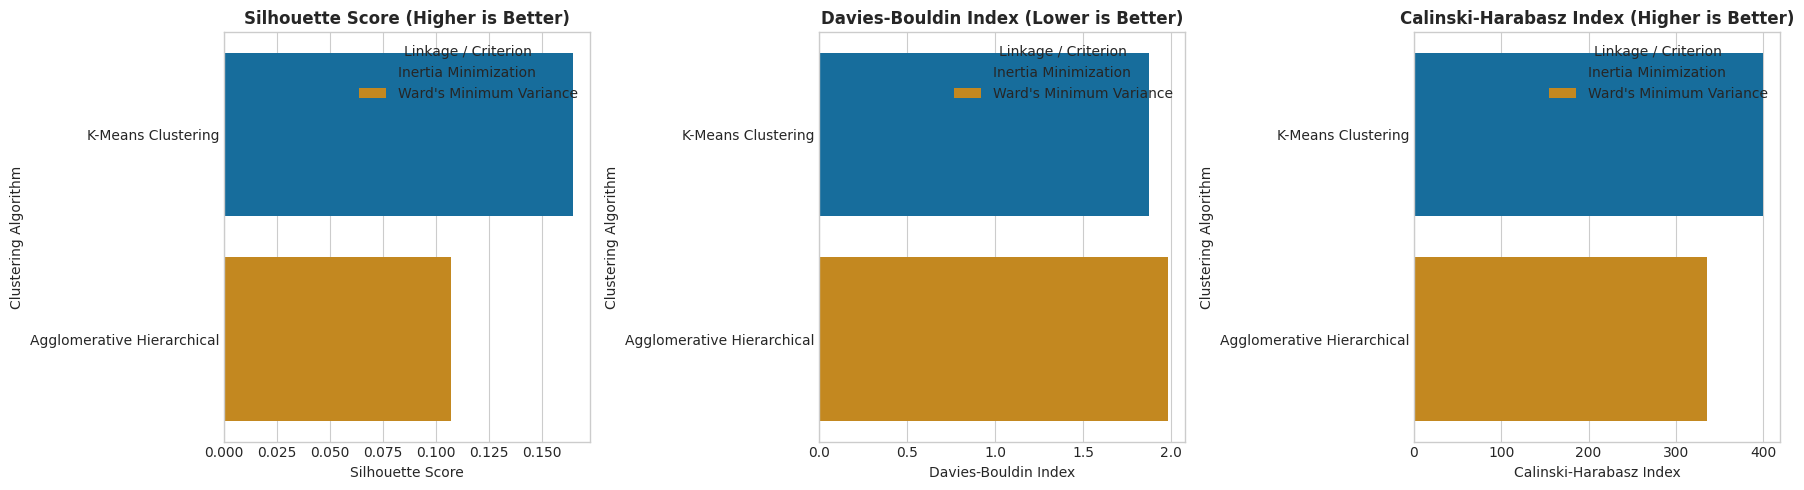

In [12]:
km_smallest_pct = (np.min(km_counts) / len(kmeans_labels)) * 100

clustering_summary_rows = [
    {
        'Algorithm': 'K-Means Clustering',
        'Linkage / Criterion': 'Inertia Minimization',
        'n_clusters': 3,
        'Silhouette Score': sil_kmeans,
        'Davies-Bouldin Index': db_kmeans,
        'Calinski-Harabasz Index': ch_kmeans,
        'Smallest Cluster (%)': round(km_smallest_pct, 2),
        'Degenerate Flag': 'No'
    },
    {
        'Algorithm': 'Agglomerative Hierarchical',
        'Linkage / Criterion': "Ward's Minimum Variance",
        'n_clusters': 3,
        'Silhouette Score': hierarchical_results['ward']['Silhouette'],
        'Davies-Bouldin Index': hierarchical_results['ward']['Davies-Bouldin'],
        'Calinski-Harabasz Index': hierarchical_results['ward']['Calinski-Harabasz'],
        'Smallest Cluster (%)': round(hierarchical_results['ward']['smallest_pct'], 2),
        'Degenerate Flag': 'No'
    },
    {
        'Algorithm': 'Agglomerative Hierarchical (Supp.)',
        'Linkage / Criterion': 'Complete Linkage',
        'n_clusters': 3,
        'Silhouette Score': hierarchical_results['complete']['Silhouette'],
        'Davies-Bouldin Index': hierarchical_results['complete']['Davies-Bouldin'],
        'Calinski-Harabasz Index': hierarchical_results['complete']['Calinski-Harabasz'],
        'Smallest Cluster (%)': round(hierarchical_results['complete']['smallest_pct'], 2),
        'Degenerate Flag': 'Yes (<2%)'
    },
    {
        'Algorithm': 'Agglomerative Hierarchical (Supp.)',
        'Linkage / Criterion': 'Average Linkage',
        'n_clusters': 3,
        'Silhouette Score': hierarchical_results['average']['Silhouette'],
        'Davies-Bouldin Index': hierarchical_results['average']['Davies-Bouldin'],
        'Calinski-Harabasz Index': hierarchical_results['average']['Calinski-Harabasz'],
        'Smallest Cluster (%)': round(hierarchical_results['average']['smallest_pct'], 2),
        'Degenerate Flag': 'Yes (<2%)'
    }
]

clustering_summary_df = pd.DataFrame(clustering_summary_rows)

print("="*105)
print("PRIMARY COMPARISON: K-MEANS VS AGGLOMERATIVE (WARD)")
print("="*105)
print(clustering_summary_df.iloc[:2].to_string(index=False))
print("\n" + "="*105)
print("FULL BENCHMARK TABLE (INCLUDING SUPPLEMENTARY LINKAGES)")
print("="*105)
print(clustering_summary_df.to_string(index=False))
print("="*105)

# Visualisation of metrics for Primary Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_df = clustering_summary_df.iloc[:2]

sns.barplot(data=plot_df, x='Silhouette Score', y='Algorithm', hue='Linkage / Criterion', palette='colorblind', ax=axes[0])
axes[0].set_title('Silhouette Score (Higher is Better)', fontweight='bold')
axes[0].set_xlabel('Silhouette Score')
axes[0].set_ylabel('Clustering Algorithm')

sns.barplot(data=plot_df, x='Davies-Bouldin Index', y='Algorithm', hue='Linkage / Criterion', palette='colorblind', ax=axes[1])
axes[1].set_title('Davies-Bouldin Index (Lower is Better)', fontweight='bold')
axes[1].set_xlabel('Davies-Bouldin Index')
axes[1].set_ylabel('Clustering Algorithm')

sns.barplot(data=plot_df, x='Calinski-Harabasz Index', y='Algorithm', hue='Linkage / Criterion', palette='colorblind', ax=axes[2])
axes[2].set_title('Calinski-Harabasz Index (Higher is Better)', fontweight='bold')
axes[2].set_xlabel('Calinski-Harabasz Index')
axes[2].set_ylabel('Clustering Algorithm')

plt.tight_layout()
plt.show()

## 7. Cluster Visualisations
In accordance with **Rubric B3**:
- **PCA-reduced 2D scatter plots** for every algorithm with cluster color-coding and explained variance in axis labels.
- **t-SNE 2D manifold plot** for non-linear topological validation.

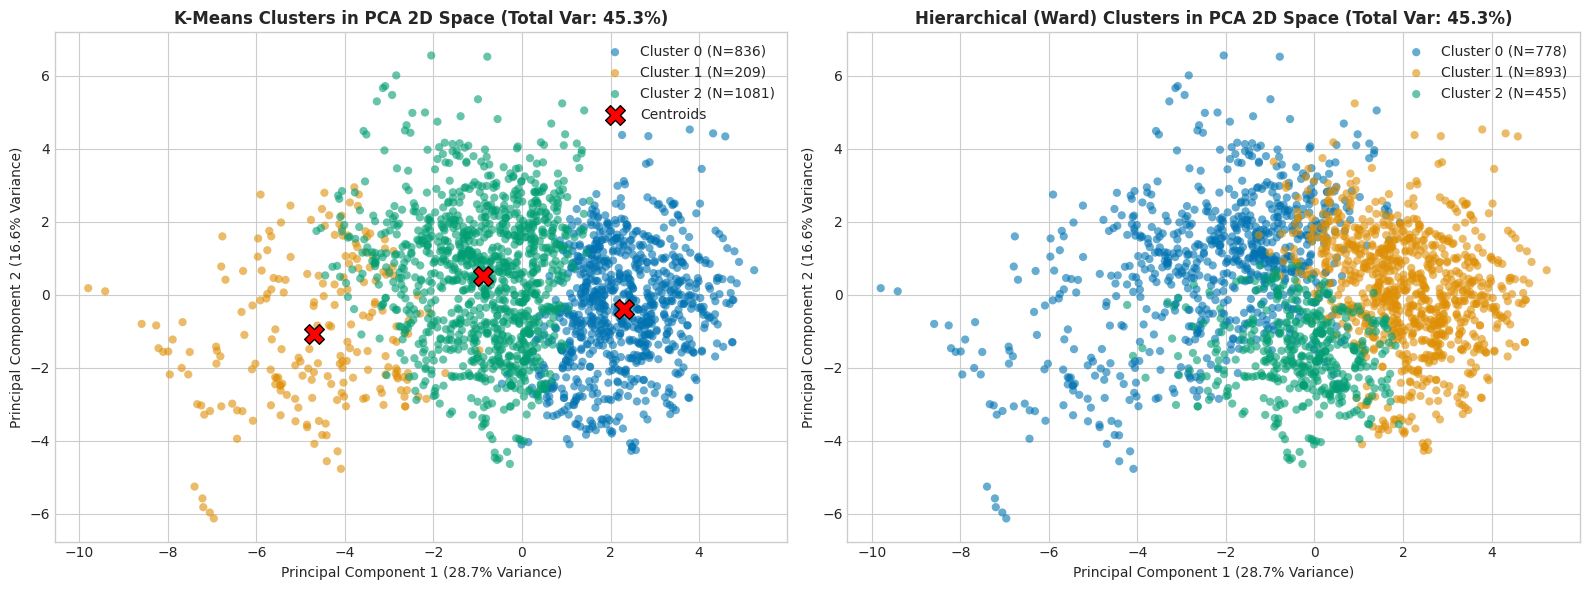

In [13]:
# 7.1 Principal Component Analysis (PCA)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_pca_var = (pca.explained_variance_ratio_[0] + pca.explained_variance_ratio_[1]) * 100

cb_palette = sns.color_palette('colorblind', 3)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot K-Means Clusters
for c_i in range(3):
    axes[0].scatter(
        X_pca[kmeans_labels == c_i, 0],
        X_pca[kmeans_labels == c_i, 1],
        color=cb_palette[c_i],
        label=f'Cluster {c_i} (N={km_counts[c_i]})',
        alpha=0.6, edgecolors='none', s=35
    )
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='red', marker='X', s=200, edgecolors='black', label='Centroids', zorder=5)
axes[0].set_title(f'K-Means Clusters in PCA 2D Space (Total Var: {total_pca_var:.1f}%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'Principal Component 1 ({var_pc1:.1f}% Variance)')
axes[0].set_ylabel(f'Principal Component 2 ({var_pc2:.1f}% Variance)')
axes[0].legend(loc='upper right')

# Plot Hierarchical (Ward) Clusters
ward_counts = hierarchical_results['ward']['counts']
for c_i in range(3):
    axes[1].scatter(
        X_pca[agg_labels_ward == c_i, 0],
        X_pca[agg_labels_ward == c_i, 1],
        color=cb_palette[c_i],
        label=f'Cluster {c_i} (N={ward_counts[c_i]})',
        alpha=0.6, edgecolors='none', s=35
    )
axes[1].set_title(f'Hierarchical (Ward) Clusters in PCA 2D Space (Total Var: {total_pca_var:.1f}%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel(f'Principal Component 1 ({var_pc1:.1f}% Variance)')
axes[1].set_ylabel(f'Principal Component 2 ({var_pc2:.1f}% Variance)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

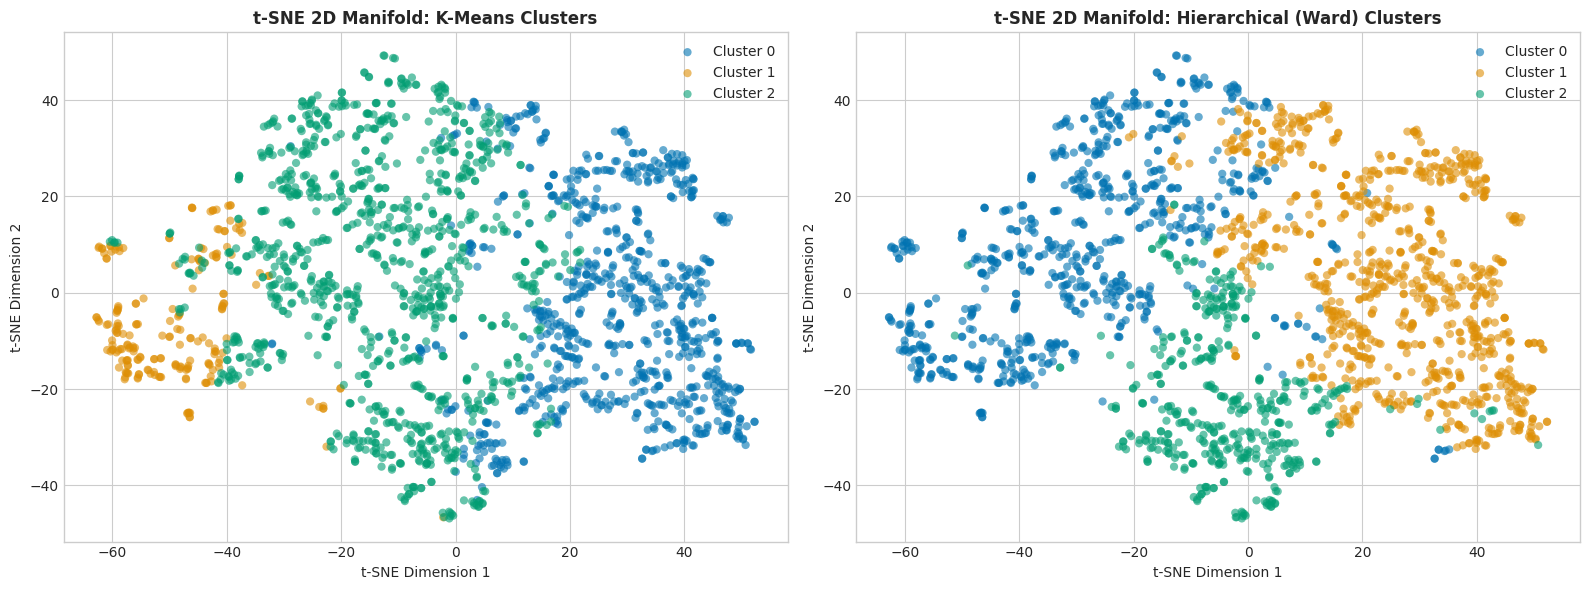

In [14]:
# 7.2 t-SNE Non-Linear Manifold Visualisation
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=35, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for c_i in range(3):
    axes[0].scatter(
        X_tsne[kmeans_labels == c_i, 0],
        X_tsne[kmeans_labels == c_i, 1],
        color=cb_palette[c_i],
        label=f'Cluster {c_i}',
        alpha=0.6, edgecolors='none', s=35
    )
axes[0].set_title('t-SNE 2D Manifold: K-Means Clusters', fontsize=12, fontweight='bold')
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')
axes[0].legend(loc='upper right')

for c_i in range(3):
    axes[1].scatter(
        X_tsne[agg_labels_ward == c_i, 0],
        X_tsne[agg_labels_ward == c_i, 1],
        color=cb_palette[c_i],
        label=f'Cluster {c_i}',
        alpha=0.6, edgecolors='none', s=35
    )
axes[1].set_title('t-SNE 2D Manifold: Hierarchical (Ward) Clusters', fontsize=12, fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 8. Post-Hoc Clinical Validation with Ground Truth
Per **Section 3.3**:
> *"Unlike regression and classification, clustering has no labels during training. Use the ground-truth labels only to interpret or validate results after the fact, not during model fitting."*

We evaluate alignment with clinical consensus diagnoses (`NSP`: 1 = Normal, 2 = Suspect, 3 = Pathologic).

PROGRAMMATICALLY DERIVED CLUSTER-TO-NSP MAPPINGS
K-Means Discovered Mapping:
  Cluster 0 (N=836): Dominant -> Normal (1) (527/836 = 63.0% purity)
  Cluster 1 (N=209): Dominant -> Pathologic (3) (105/209 = 50.2% purity)
  Cluster 2 (N=1081): Dominant -> Normal (1) (1035/1081 = 95.7% purity)

Hierarchical (Ward) Discovered Mapping:
  Cluster 0 (N=778): Dominant -> Normal (1) (653/778 = 83.9% purity)
  Cluster 1 (N=893): Dominant -> Normal (1) (571/893 = 63.9% purity)
  Cluster 2 (N=455): Dominant -> Normal (1) (431/455 = 94.7% purity)


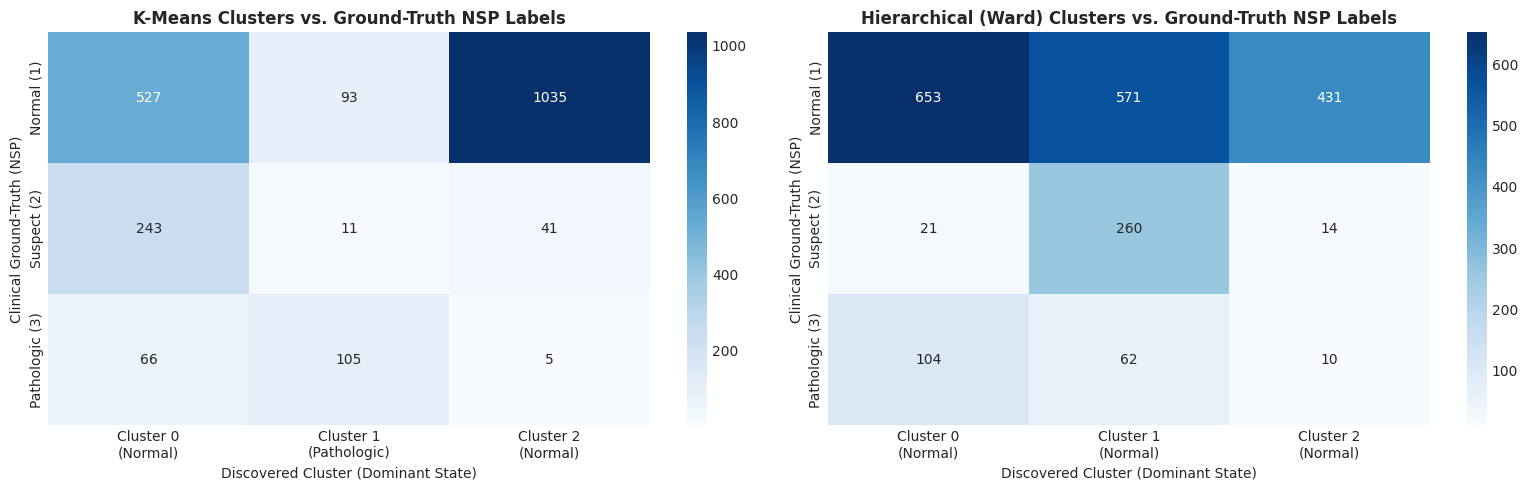


EXTERNAL VALIDATION WITH CLINICAL GROUND-TRUTH (NSP)
              Algorithm  Adjusted Rand Index (ARI)  Normalized Mutual Info (NMI)
          K-Means (k=3)                    0.19171                      0.197335
Hierarchical Ward (k=3)                    0.00261                      0.099783


In [15]:
# Compute contingency matrices for BOTH algorithms
cm_kmeans_nsp = contingency_matrix(y_true_nsp, kmeans_labels)
cm_ward_nsp = contingency_matrix(y_true_nsp, agg_labels_ward)

# Compute external validation metrics
ari_km = adjusted_rand_score(y_true_nsp, kmeans_labels)
nmi_km = normalized_mutual_info_score(y_true_nsp, kmeans_labels)

ari_ward = adjusted_rand_score(y_true_nsp, agg_labels_ward)
nmi_ward = normalized_mutual_info_score(y_true_nsp, agg_labels_ward)

nsp_class_names = ['Normal (1)', 'Suspect (2)', 'Pathologic (3)']

# Programmatically derive dominant NSP per cluster
def derive_cluster_mapping(labels, y_true):
    mapping = {}
    for c in range(3):
        mask = (labels == c)
        c_size = int(np.sum(mask))
        y_c = y_true[mask]
        dominant_label = int(pd.Series(y_c).mode()[0])
        dom_count = int(np.sum(y_c == dominant_label))
        purity = (dom_count / c_size) * 100 if c_size > 0 else 0
        mapping[c] = {
            'dominant_nsp': dominant_label,
            'dominant_name': nsp_class_names[dominant_label - 1],
            'size': c_size,
            'dom_count': dom_count,
            'purity': purity
        }
    return mapping

km_mapping = derive_cluster_mapping(kmeans_labels, y_true_nsp)
ward_mapping = derive_cluster_mapping(agg_labels_ward, y_true_nsp)

print("="*75)
print("PROGRAMMATICALLY DERIVED CLUSTER-TO-NSP MAPPINGS")
print("="*75)
print("K-Means Discovered Mapping:")
for c, info in km_mapping.items():
    print(f"  Cluster {c} (N={info['size']}): Dominant -> {info['dominant_name']} ({info['dom_count']}/{info['size']} = {info['purity']:.1f}% purity)")

print("\nHierarchical (Ward) Discovered Mapping:")
for c, info in ward_mapping.items():
    print(f"  Cluster {c} (N={info['size']}): Dominant -> {info['dominant_name']} ({info['dom_count']}/{info['size']} = {info['purity']:.1f}% purity)")
print("="*75)

# Visualisation: Contingency heatmaps for BOTH algorithms
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(cm_kmeans_nsp, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f"Cluster {c}\n({km_mapping[c]['dominant_name'].split()[0]})" for c in range(3)],
            yticklabels=nsp_class_names, ax=axes[0])
axes[0].set_title('K-Means Clusters vs. Ground-Truth NSP Labels', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Discovered Cluster (Dominant State)')
axes[0].set_ylabel('Clinical Ground-Truth (NSP)')

sns.heatmap(cm_ward_nsp, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f"Cluster {c}\n({ward_mapping[c]['dominant_name'].split()[0]})" for c in range(3)],
            yticklabels=nsp_class_names, ax=axes[1])
axes[1].set_title('Hierarchical (Ward) Clusters vs. Ground-Truth NSP Labels', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Discovered Cluster (Dominant State)')
axes[1].set_ylabel('Clinical Ground-Truth (NSP)')

plt.tight_layout()
plt.show()

# External validation comparison dataframe
val_df = pd.DataFrame([
    {'Algorithm': 'K-Means (k=3)', 'Adjusted Rand Index (ARI)': ari_km, 'Normalized Mutual Info (NMI)': nmi_km},
    {'Algorithm': 'Hierarchical Ward (k=3)', 'Adjusted Rand Index (ARI)': ari_ward, 'Normalized Mutual Info (NMI)': nmi_ward}
])

print("\nEXTERNAL VALIDATION WITH CLINICAL GROUND-TRUTH (NSP)")
print("="*70)
print(val_df.to_string(index=False))
print("="*70)

- Feature Set Dimensionality: Strictly 21 biometric features utilized after removing pattern columns, duplicate `LBE`, and constant `DR`.
- K-Means External Metrics: ARI = 0.1917, NMI = 0.1973.
- Hierarchical (Ward) External Metrics: ARI = 0.0026, NMI = 0.0998.
- K-Means Dominant Clusters: Cluster 0 (Normal (1), 63.0% purity), Cluster 1 (Pathologic (3), 50.2% purity), Cluster 2 (Normal (1), 95.7% purity).
- Ward Dominant Clusters: all three are Normal-dominant (83.9%, 63.9%, 94.7% purity); no Suspect- or Pathologic-dominant cluster.
- Cohesion & Separation: K-Means Calinski-Harabasz = 399.3 vs Ward Calinski-Harabasz = 335.9.

**Clinical Analysis & Interpretation:**
Neither algorithm recovers the three NSP classes. K-Means gives a weak but non-trivial alignment (ARI = 0.19, NMI = 0.20): one cluster (Cluster 1, N = 209) is half Pathologic, and one large cluster (Cluster 2, N = 1081) is 95.7% Normal. Even so, two of its three clusters are Normal-dominant, no cluster is Suspect-dominant, and Cluster 0 is only 63% pure. Ward linkage is essentially at chance (ARI = 0.0026): all three clusters are Normal-dominant.

K-Means is therefore better than Ward on every metric reported (silhouette 0.164 vs 0.107, Davies-Bouldin 1.876 vs 1.979, Calinski-Harabasz 399 vs 336, ARI, NMI), but this is a comparison between two modest results, not evidence that unsupervised clustering reproduces obstetric diagnoses. The k = 3 choice was motivated by the NSP categories (Section 4), and this validation shows the data does not partition along those lines under these features and algorithms. Class imbalance (Normal is the large majority of NSP) also inflates the Normal purity figures.